In [ ]:
!

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def convert_to_rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [4]:
captures = cv2.VideoCapture(r'Data/vtest.avi')

In [8]:
captures

< cv2.VideoCapture 0x147d77c90>

In [5]:
ret, frame = captures.read()

In [9]:
captures.get(cv2.CAP_PROP_FRAME_COUNT)

795.0

In [13]:
random_frames = captures.get(cv2.CAP_PROP_FRAME_COUNT) * np.random.uniform(size=30)

In [14]:
random_frames

array([153.26239612, 763.53716254, 688.27355528, 439.13309111,
       119.697358  , 474.55262456, 733.79691189, 767.49780126,
       510.56586014, 552.2947679 , 452.5289185 , 509.16719356,
       694.72282717,  30.8424367 , 440.39054593, 396.69350377,
       764.93957955, 769.65293147, 653.61183014, 536.95516807,
         2.25160946, 476.38841952,  49.9057246 , 744.6468142 ,
       448.28667762,  10.30841114, 241.19834477, 740.80833315,
       264.38608802, 268.50110813])

In [15]:
frames = []

for frame_id in random_frames:
    captures.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ret, frame = captures.read()
    frames.append(frame)

captures.release()

In [ ]:
len(frames)

30

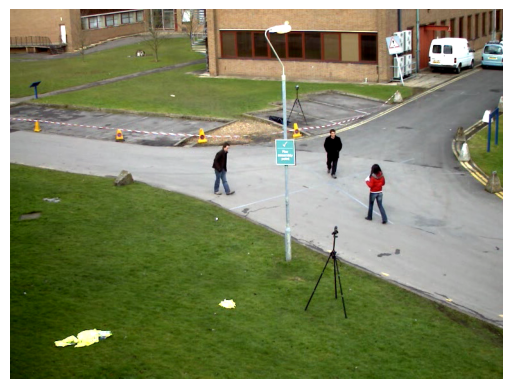

In [19]:
plt.imshow(convert_to_rgb(frames[10]))
plt.axis('off')
plt.show()

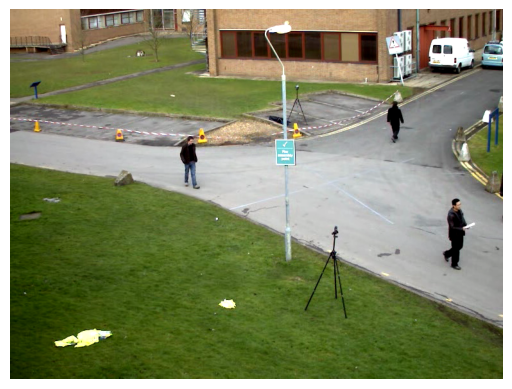

In [20]:
plt.imshow(convert_to_rgb(frames[15]))
plt.axis('off')
plt.show()

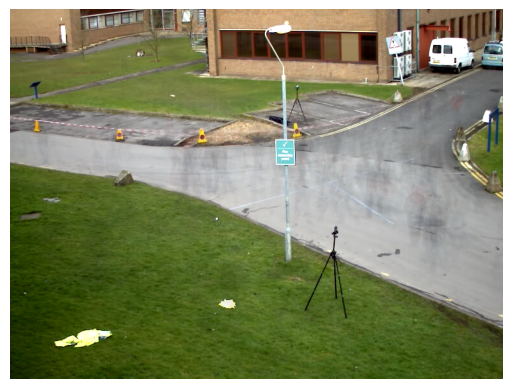

In [22]:
avg_frame = np.average(frames,axis=0).astype(np.uint8)

plt.imshow(convert_to_rgb(avg_frame))
plt.axis('off')
plt.show()

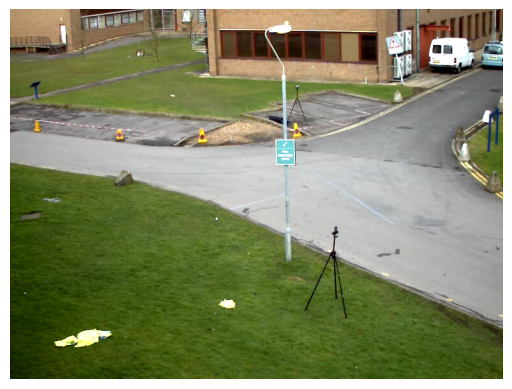

In [23]:
median_frame = np.median(frames,axis=0).astype(np.uint8)

plt.imshow(convert_to_rgb(median_frame))
plt.axis('off')
plt.show()

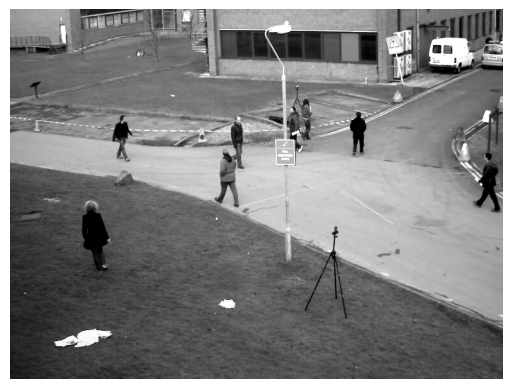

In [27]:
framex = frames[12]

gray_frame = cv2.cvtColor(framex, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_frame, cmap='gray')
plt.axis('off')
plt.show()

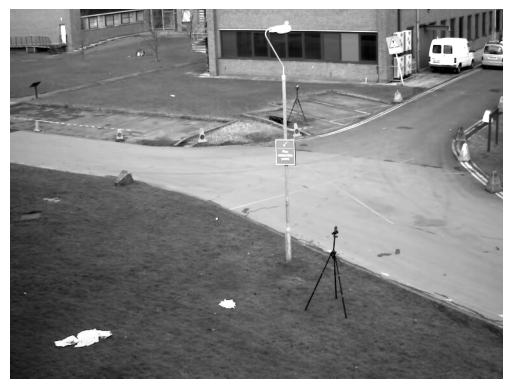

In [28]:
median_frame = np.median(frames,axis=0).astype(np.uint8)

gray_background = cv2.cvtColor(median_frame, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_background, cmap='gray')
plt.axis('off')
plt.show()

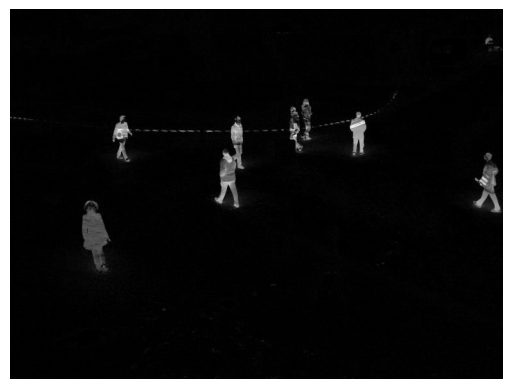

In [29]:
background_remove = cv2.absdiff(gray_frame, gray_background)

plt.imshow(background_remove, cmap='gray')
plt.axis('off')
plt.show()

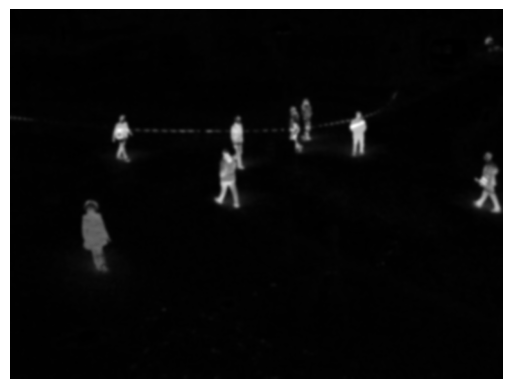

In [ ]:
background_remove_blur = cv2.GaussianBlur(background_remove, (11, 11), 0)

plt.imshow(background_remove_blur, cmap='gray')
plt.axis('off')
plt.show()  

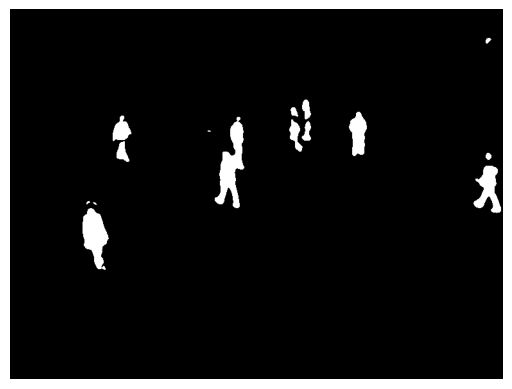

In [32]:
_,frametr = cv2.threshold(background_remove_blur, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)

plt.imshow(frametr, cmap='gray')
plt.axis('off')
plt.show()  

In [33]:
(countours ,_) = cv2.findContours(frametr,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

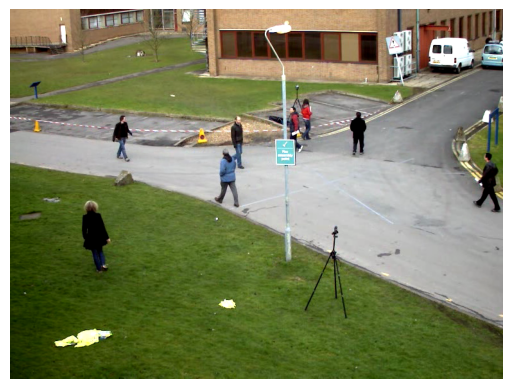

In [43]:
plt.imshow(convert_to_rgb(framex))
plt.axis('off')
plt.show()  

In [47]:
fff = cv2.cvtColor(frametr, cv2.COLOR_GRAY2BGR)
for co in countours:
    x,y,w,h = cv2.boundingRect(co)
    cv2.rectangle(fff,(x,y),(x+w,y+h),(0,255,0),2)

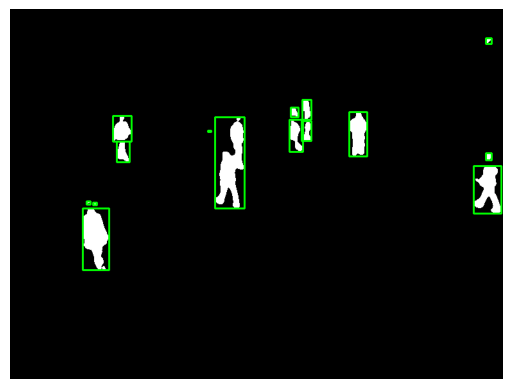

In [48]:
plt.imshow(fff)
plt.axis('off')
plt.show()  

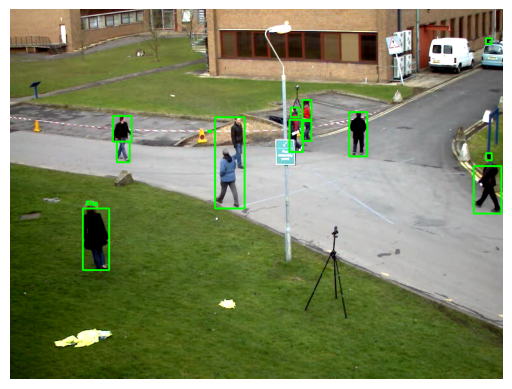

In [45]:
plt.imshow(convert_to_rgb(framex))
plt.axis('off')
plt.show()  

In [53]:
background_subtract = cv2.createBackgroundSubtractorMOG2()
captures = cv2.VideoCapture(r'Data/background video _ people _ walking _.mp4')

while captures.isOpened():
    ret, frame = captures.read()
    if not ret:
        break
    fg_mask = background_subtract.apply(frame)
    (countours ,_) = cv2.findContours(fg_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for co in countours:
        if cv2.contourArea(co) > 500:
            x,y,w,h = cv2.boundingRect(co)
            cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)

    cv2.imshow('Foreground Mask', fg_mask)
    cv2.imshow('Tracked Objects', frame)

    if cv2.waitKey(30) & 0xFF == ord('q'):
        break
captures.release()
cv2.destroyAllWindows()
